# Put/Call Ratio - Deep Analysis (6 coins)

Live Deribit option chains for BTC, ETH, SOL, BNB, XRP, ZEC.

**Every chart is followed by an explanation of what it tells you.**

**Sections:**

1. Fetch live data
2. PCR per coin - table + interpretation
3. Bar chart comparison
4. Gauge dial per coin
5. OI breakdown (calls vs puts)
6. Volume vs OI divergence
7. PCR by expiry (term structure of sentiment)
8. PCR by strike (where is fear concentrated?)
9. OI walls (support / resistance)
10. Skew (put IV minus call IV)
11. Composite sentiment score
12. Final recommendations

## Setup

In [28]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timezone
import time

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
plt.rcParams['figure.figsize'] = (13, 5)

DERIBIT = 'https://www.deribit.com/api/v2/public'
COINS = ['BTC', 'ETH']
print('ready')

ready


## 1. Fetch live option chains

One request per coin. Coins without listed options are skipped.

In [29]:
def fetch_chain(currency):
    r = requests.get(f'{DERIBIT}/get_book_summary_by_currency',
                     params={'currency': currency, 'kind': 'option'}, timeout=20)
    r.raise_for_status()
    return r.json()['result']


def parse_name(name):
    parts = name.split('-')
    if len(parts) != 4:
        return None
    try:
        _, exp, strike, kind = parts
        dt = datetime.strptime(exp, '%d%b%y').replace(tzinfo=timezone.utc, hour=8)
        return int(dt.timestamp() * 1000), float(strike), kind
    except (ValueError, IndexError):
        return None


frames, available = [], []
for cur in COINS:
    try:
        raw = fetch_chain(cur)
        now_ms = int(time.time() * 1000)
        rows = []
        for r in raw:
            p = parse_name(r['instrument_name'])
            if p is None: continue
            rows.append({
                'underlying': cur, 'expiry': p[0], 'strike': p[1], 'kind': p[2],
                'ts': now_ms,
                'mark': r.get('mark_price'),
                'bid': r.get('bid_price'), 'ask': r.get('ask_price'),
                'iv': r.get('mark_iv'),
                'oi': r.get('open_interest'),
                'volume': r.get('volume'),
                'underlying_price': r.get('underlying_price'),
            })
        if not rows:
            print(f'{cur:<5} no options listed')
            continue
        frames.append(pd.DataFrame(rows))
        available.append(cur)
        print(f'{cur:<5} {len(rows):>4} contracts')
    except Exception as e:
        print(f'{cur:<5} failed - {e}')
    time.sleep(0.3)

df = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
df['days'] = (df['expiry'] - df['ts']) / 86_400_000
df['iv_dec'] = df['iv'] / 100.0

# spot estimate per coin
spots = {}
for cur in available:
    s = df[df.underlying == cur]
    v = s[s.underlying_price.notna()]
    spots[cur] = float(v.underlying_price.iloc[0]) if len(v) else float(s.strike.median())

print(f'\ntotal contracts: {len(df)}')
print('\nspots:')
for k, v in spots.items(): print(f'  {k:<5} {v:,.2f}')

BTC    876 contracts


ETH    734 contracts

total contracts: 1610

spots:
  BTC   80,165.98
  ETH   2,315.47


## 2. PCR per coin - the main table

**What this tells you:**

- **PCR(OI) < 0.7** → market is holding far more calls than puts → everyone is betting up → when upside disappoints, they sell calls, adding downside pressure. **Buy puts.**
- **PCR(OI) > 1.3** → market is holding far more puts than calls → everyone is hedging/bearish → when downside disappoints, they unwind puts (buying), adding upside pressure. **Buy calls.**
- **0.85-1.15** → no edge from PCR alone.

In [30]:
def interpret(ratio):
    if ratio > 1.5:  return 'EXTREME FEAR',  'buy CALLS'
    if ratio > 1.15: return 'moderate fear', 'favor calls'
    if ratio > 0.85: return 'balanced',      'no edge'
    if ratio > 0.65: return 'moderate greed','favor puts'
    return 'EXTREME GREED', 'buy PUTS'

pcr_data = []
for cur in available:
    s = df[df.underlying == cur]
    oic = s[s.kind=='C'].oi.sum()
    oip = s[s.kind=='P'].oi.sum()
    vc  = s[s.kind=='C'].volume.sum()
    vp  = s[s.kind=='P'].volume.sum()
    label, action = interpret(oip/max(oic,1))
    pcr_data.append({
        'coin':    cur,
        'call_oi': oic, 'put_oi': oip,
        'call_vol':vc, 'put_vol':vp,
        'pcr_oi':  oip / max(oic,1),
        'pcr_vol': vp  / max(vc,1),
        'label':   label,
        'action':  action,
        'contracts': len(s),
    })

pcr = pd.DataFrame(pcr_data).sort_values('pcr_oi', ascending=False).reset_index(drop=True)
pcr

,coin,call_oi,put_oi,call_vol,put_vol,pcr_oi,pcr_vol,label,action,contracts
0,BTC,241918.2,144499.4,4145.8,4123.9,0.597307,0.994718,EXTREME GREED,buy PUTS,876
1,ETH,1002984.0,494479.0,23624.0,19549.0,0.493008,0.827506,EXTREME GREED,buy PUTS,734


## 3. Bar chart comparison

**What this tells you:**

- Height of each bar = how fearful (right) or greedy (left) each coin's market is
- The dashed line at 1.0 is neutral
- **Coins above 1.15 (red zone)** have crowded fear → contrarian call buy
- **Coins below 0.85 (green zone)** have crowded greed → contrarian put buy
- Comparing bars tells you **which coin has the strongest edge right now**

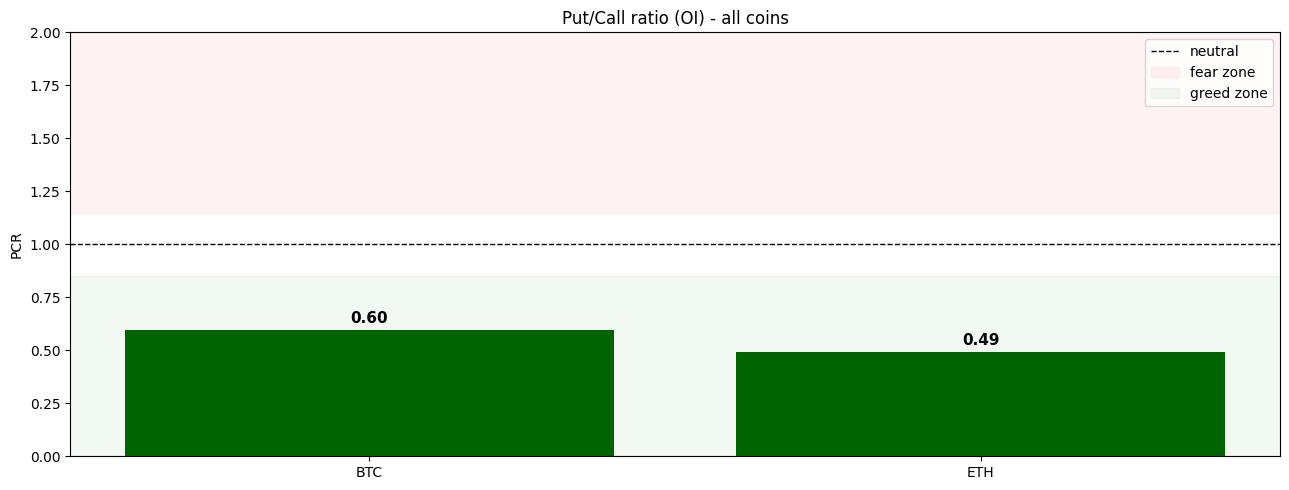

In [31]:
fig, ax = plt.subplots(figsize=(13, 5))
colors = []
for v in pcr.pcr_oi:
    if v > 1.5:   colors.append('darkred')
    elif v > 1.15: colors.append('crimson')
    elif v > 0.85: colors.append('gray')
    elif v > 0.65: colors.append('seagreen')
    else:          colors.append('darkgreen')

bars = ax.bar(pcr.coin, pcr.pcr_oi, color=colors)
ax.axhline(1.0,  color='black', lw=1.0, ls='--', label='neutral')
ax.axhspan(1.15, 2.0, color='red',  alpha=0.05, label='fear zone')
ax.axhspan(0.0,  0.85, color='green', alpha=0.05, label='greed zone')
for b, v in zip(bars, pcr.pcr_oi):
    ax.text(b.get_x() + b.get_width()/2, v + 0.03, f'{v:.2f}',
            ha='center', fontsize=11, fontweight='bold')
ax.set_title('Put/Call ratio (OI) - all coins')
ax.set_ylabel('PCR')
ax.set_ylim(0, max(2.0, pcr.pcr_oi.max() * 1.1))
ax.legend(loc='upper right')
plt.tight_layout(); plt.show()

## 4. Gauge dial per coin

**What this tells you:**

- Green half = greedy (put-buying opportunity)
- Red half = fearful (call-buying opportunity)
- Needle position = current PCR
- **The further the needle from center, the stronger the contrarian trade**

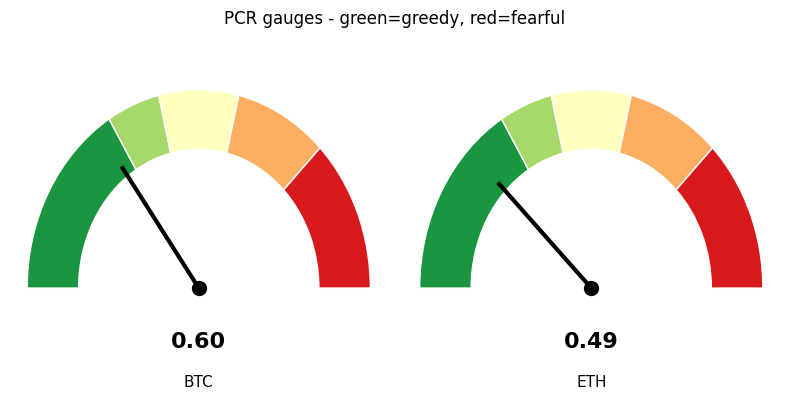

In [32]:
def draw_gauge(ax, ratio, title):
    zones = [(0.0, 0.65, '#1a9641'), (0.65, 0.85, '#a6d96a'),
             (0.85, 1.15, '#ffffbf'), (1.15, 1.5, '#fdae61'),
             (1.5, 2.0, '#d7191c')]
    for lo, hi, color in zones:
        t1 = 180 - (hi/2.0)*180
        t2 = 180 - (lo/2.0)*180
        ax.add_patch(plt.matplotlib.patches.Wedge(
            (0,0), 1, t1, t2, width=0.3, facecolor=color, edgecolor='white'))
    clamped = min(ratio, 2.0)
    theta = np.pi * (1 - clamped/2.0)
    ax.plot([0, np.cos(theta)*0.75], [0, np.sin(theta)*0.75], 'k-', lw=3)
    ax.plot(0, 0, 'ko', ms=10)
    ax.text(0, -0.3, f'{ratio:.2f}', ha='center', fontsize=16, fontweight='bold')
    ax.text(0, -0.5, title, ha='center', fontsize=11)
    ax.set_xlim(-1.1, 1.1); ax.set_ylim(-0.6, 1.1)
    ax.axis('off')

n = len(pcr)
fig, axes = plt.subplots(1, n, figsize=(4*n, 4))
if n == 1: axes = [axes]
for ax, (_, r) in zip(axes, pcr.iterrows()):
    draw_gauge(ax, r['pcr_oi'], r['coin'])
plt.suptitle('PCR gauges - green=greedy, red=fearful', fontsize=12, y=1.03)
plt.tight_layout(); plt.show()

## 5. OI breakdown: calls vs puts

**What this tells you:**

- The gap between green and red bars = **how lopsided the market is**
- Big green bar = lots of people betting up (vulnerable to downside)
- Big red bar = lots of people hedging (vulnerable to squeeze up)
- Coins where the bars are nearly equal = no edge

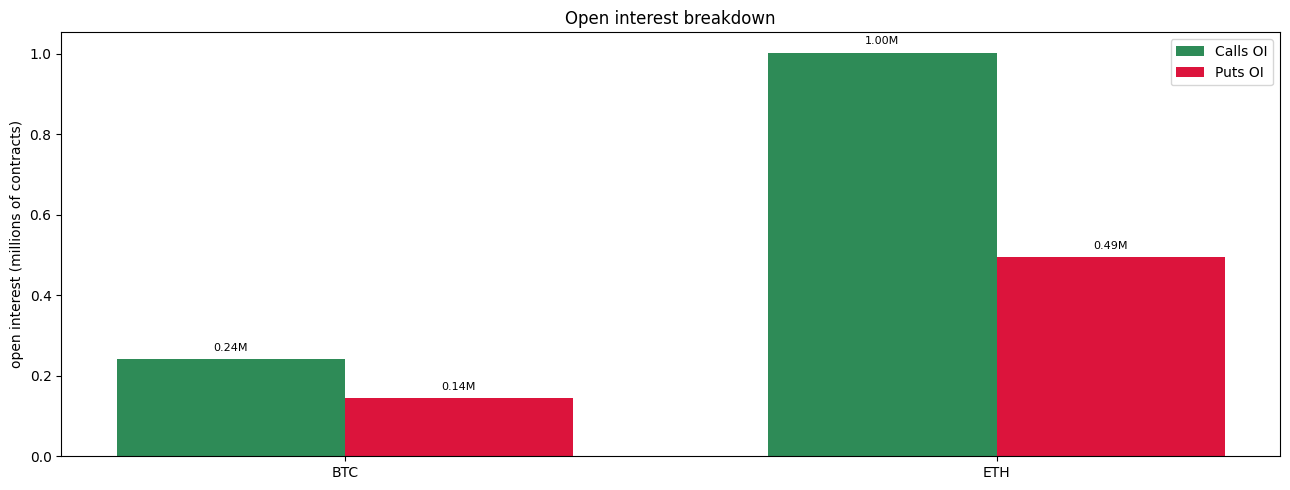

In [33]:
fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(pcr))
w = 0.35
ax.bar(x - w/2, pcr.call_oi / 1e6, w, label='Calls OI', color='seagreen')
ax.bar(x + w/2, pcr.put_oi  / 1e6, w, label='Puts OI',  color='crimson')
ax.set_xticks(x); ax.set_xticklabels(pcr.coin)
ax.set_ylabel('open interest (millions of contracts)')
ax.set_title('Open interest breakdown')
ax.legend()
for i, (c, p) in enumerate(zip(pcr.call_oi, pcr.put_oi)):
    ax.text(i - w/2, c/1e6 + 0.02, f'{c/1e6:.2f}M', ha='center', fontsize=8)
    ax.text(i + w/2, p/1e6 + 0.02, f'{p/1e6:.2f}M', ha='center', fontsize=8)
plt.tight_layout(); plt.show()

## 6. Divergence: volume PCR vs OI PCR

**What this tells you:**

- **PCR(OI)** = what people are **holding** (accumulated over weeks)
- **PCR(volume)** = what people **traded today** (fresh flow)
- **When volume PCR is much higher than OI PCR** → today's flow is much more bearish than the standing position → **early reversal signal**
- **When volume PCR is much lower** → today's flow is more bullish than positions → **early momentum signal**
- When they agree → the signal is strong

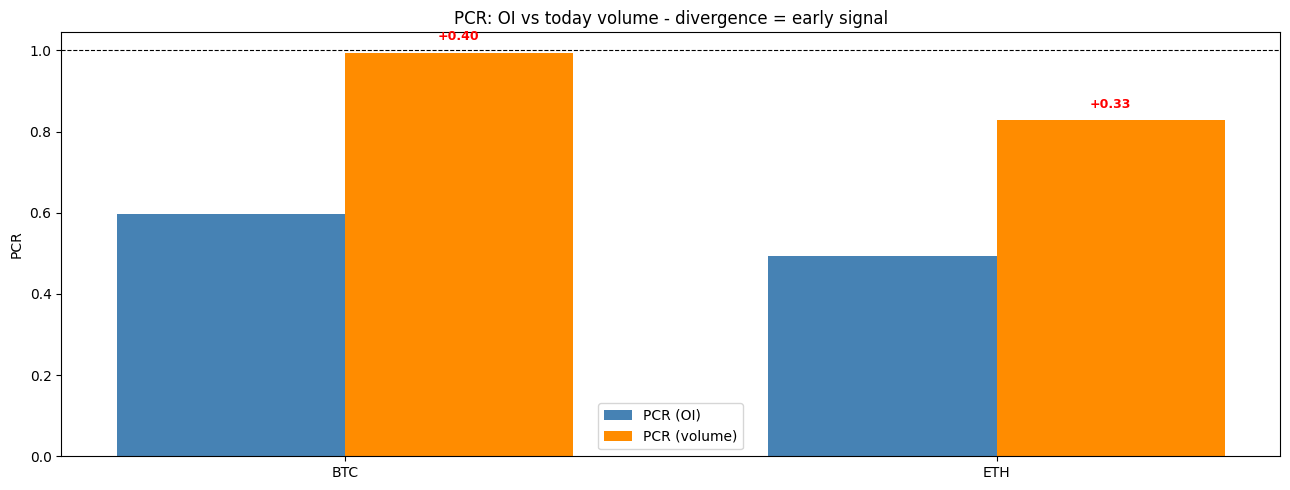


Divergence analysis:
  BTC    vol PCR +0.40 higher -> today's flow is BEARISH (early reversal)
  ETH    vol PCR +0.33 higher -> today's flow is BEARISH (early reversal)


In [34]:
fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(pcr))
w = 0.35
ax.bar(x - w/2, pcr.pcr_oi,  w, label='PCR (OI)',     color='steelblue')
ax.bar(x + w/2, pcr.pcr_vol, w, label='PCR (volume)', color='darkorange')
ax.axhline(1.0, color='black', lw=0.8, ls='--')
ax.set_xticks(x); ax.set_xticklabels(pcr.coin)
ax.set_title('PCR: OI vs today volume - divergence = early signal')
ax.set_ylabel('PCR')
ax.legend()

for i, (o, v) in enumerate(zip(pcr.pcr_oi, pcr.pcr_vol)):
    div = v - o
    if abs(div) > 0.2:
        ax.annotate(f'{div:+.2f}', (i + w/2, v + 0.03),
                    ha='center', color='red', fontsize=9, fontweight='bold')
plt.tight_layout(); plt.show()

print('\nDivergence analysis:')
for _, r in pcr.iterrows():
    div = r['pcr_vol'] - r['pcr_oi']
    if div > 0.3:
        print(f"  {r['coin']:<5}  vol PCR {div:+.2f} higher -> today's flow is BEARISH (early reversal)")
    elif div < -0.3:
        print(f"  {r['coin']:<5}  vol PCR {div:+.2f} lower  -> today's flow is BULLISH (early momentum)")
    else:
        print(f"  {r['coin']:<5}  vol PCR {div:+.2f}     -> OI and volume agree")

## 7. PCR by expiry - term structure of sentiment

**What this tells you:**

- **Uptrending line** (near-term PCR < far-term PCR) → near-term calm, long-term fear. Traders are hedging future risk but not today.
- **Downtrending line** (near-term PCR > far-term PCR) → near-term panic. Short-dated puts being bought heavily → **bounce likely soon** (panic tends to reverse).
- **Flat line** → no term structure edge.

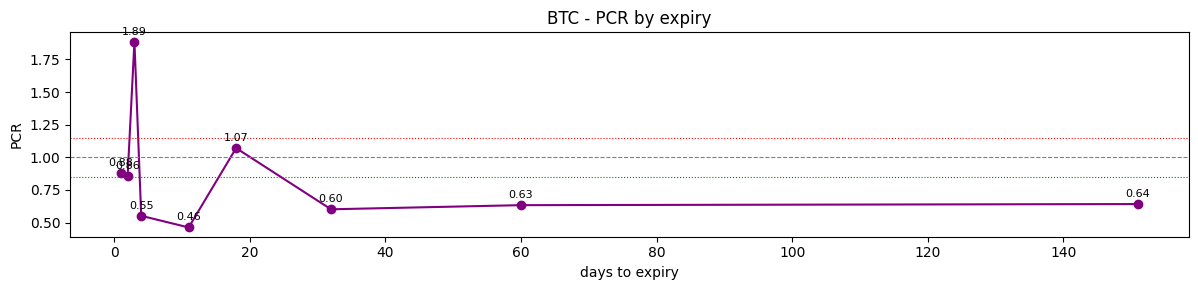

  BTC: near-term PCR >> far-term -> PANIC in short expiries (bounce likely)


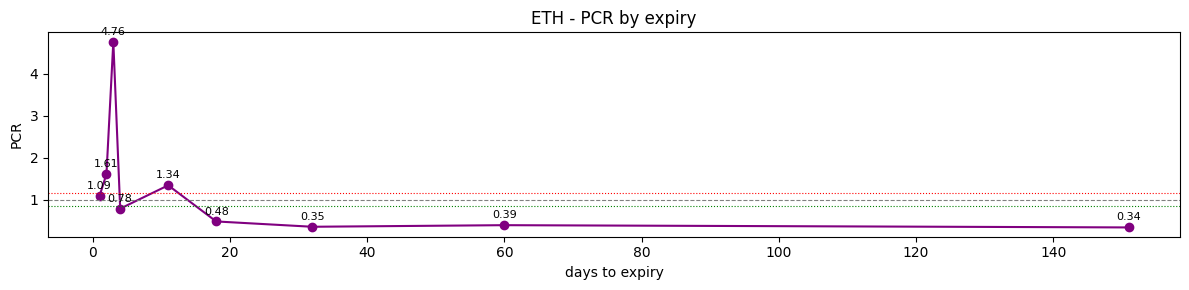

  ETH: near-term PCR >> far-term -> PANIC in short expiries (bounce likely)


In [35]:
for cur in pcr.coin:
    s = df[df.underlying == cur]
    if len(s) == 0: continue
    by_exp = s.groupby(['expiry', 'kind']).oi.sum().unstack('kind').fillna(0)
    by_exp['days'] = (by_exp.index - int(time.time() * 1000)) / 86_400_000
    by_exp = by_exp[(by_exp.days > 0) & (by_exp.days < 200)].sort_values('days')
    if len(by_exp) < 2: continue
    by_exp['pcr'] = by_exp['P'] / by_exp['C'].replace(0, np.nan)

    fig, ax = plt.subplots(figsize=(12, 3))
    ax.plot(by_exp.days, by_exp.pcr, marker='o', lw=1.5, color='purple', ms=6)
    ax.axhline(1.0, ls='--', color='gray', lw=0.8)
    ax.axhline(1.15, ls=':', color='red', lw=0.8)
    ax.axhline(0.85, ls=':', color='green', lw=0.8)
    ax.set_title(f'{cur} - PCR by expiry')
    ax.set_xlabel('days to expiry'); ax.set_ylabel('PCR')
    for d, p in zip(by_exp.days, by_exp.pcr):
        if pd.notna(p):
            ax.annotate(f'{p:.2f}', (d, p), textcoords='offset points',
                        xytext=(0, 5), ha='center', fontsize=8)
    plt.tight_layout(); plt.show()

    if by_exp.pcr.iloc[0] > by_exp.pcr.iloc[-1] * 1.15:
        print(f'  {cur}: near-term PCR >> far-term -> PANIC in short expiries (bounce likely)')
    elif by_exp.pcr.iloc[-1] > by_exp.pcr.iloc[0] * 1.15:
        print(f'  {cur}: far-term PCR >> near-term -> future fear but calm now')

## 8. PCR by strike - where is fear concentrated?

**What this tells you:**

- **Peak at low strikes** (below spot) = puts bought at deep OTM strikes = **crash protection**. Traders expect a big drop or are hedging.
- **Peak at high strikes** (above spot) = puts bought at deep OTM strikes = **bullish confirmation** (those puts are lottery tickets, likely to expire worthless, giving edge to call buyers)
- **Peak near spot** = at-the-money fear, most meaningful signal

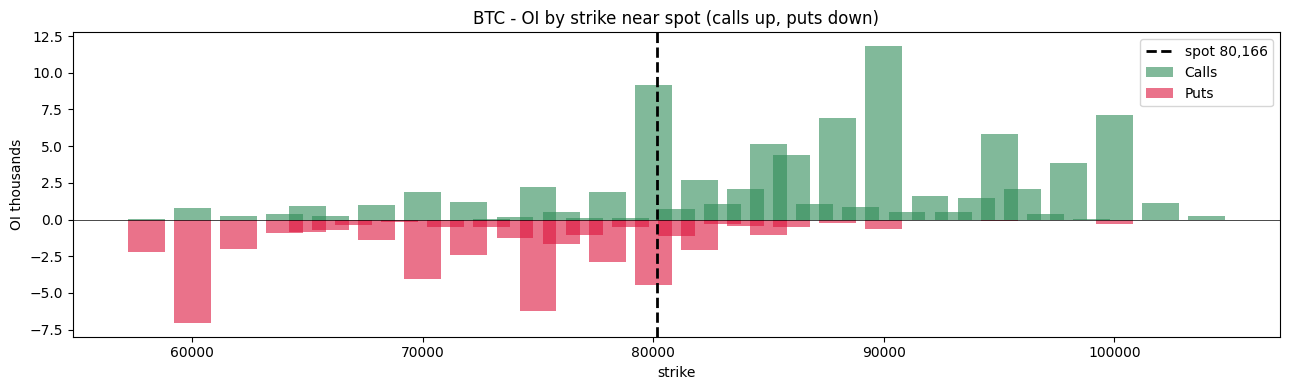

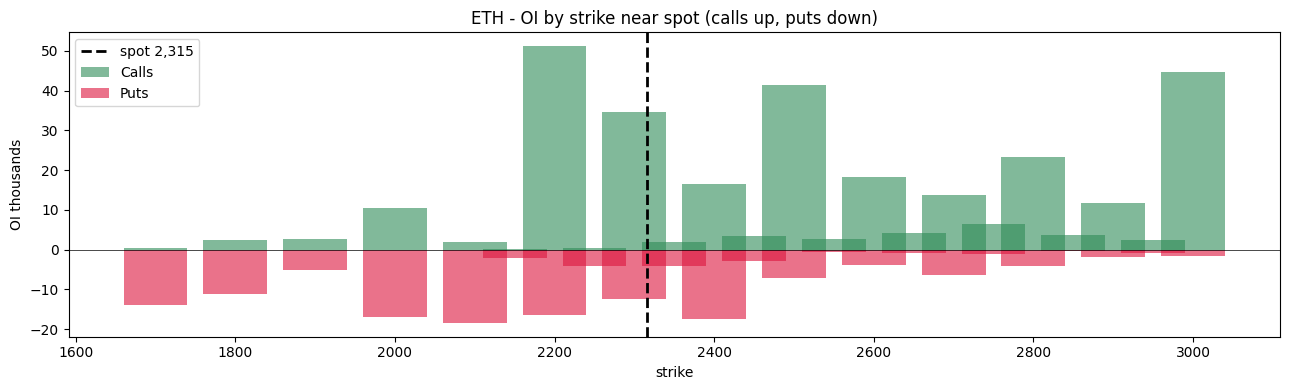

In [36]:
for cur in pcr.coin:
    s = df[(df.underlying == cur) & (df.days.between(7, 90))].copy()
    if len(s) == 0: continue
    spot = spots[cur]
    s['moneyness'] = (s.strike - spot) / spot * 100
    s = s[s.moneyness.between(-30, 30)]
    if len(s) == 0: continue

    pivot = s.pivot_table(index='strike', columns='kind', values='oi', aggfunc='sum').fillna(0)
    pivot['pcr'] = pivot['P'] / pivot['C'].replace(0, np.nan)

    fig, ax = plt.subplots(figsize=(13, 4))
    x = pivot.index
    ax.bar(x, pivot['C']/1e3, color='seagreen', alpha=0.6, label='Calls', width=(x[1]-x[0])*0.8)
    ax.bar(x, -pivot['P']/1e3, color='crimson', alpha=0.6, label='Puts',  width=(x[1]-x[0])*0.8)
    ax.axvline(spot, color='black', lw=2, ls='--', label=f'spot {spot:,.0f}')
    ax.axhline(0, color='black', lw=0.5)
    ax.set_title(f'{cur} - OI by strike near spot (calls up, puts down)')
    ax.set_xlabel('strike'); ax.set_ylabel('OI thousands')
    ax.legend()
    plt.tight_layout(); plt.show()

## 9. OI walls - where price will get pinned

**What this tells you:**

- **Call wall** (highest call OI strike) = **resistance**. As price approaches, call sellers hedge by selling spot → pressure down.
- **Put wall** (highest put OI strike) = **support**. As price approaches, put sellers hedge by buying spot → pressure up.
- **As a buyer:** buy calls **above** the call wall (breakout) or buy puts **at** the put wall (bounce play)

In [37]:
walls = {}
for cur in pcr.coin:
    s = df[df.underlying == cur]
    if len(s) == 0: continue
    pivot = s.pivot_table(index='strike', columns='kind', values='oi', aggfunc='sum').fillna(0)
    if 'C' in pivot.columns and 'P' in pivot.columns:
        walls[cur] = {
            'call_wall': float(pivot['C'].idxmax()),
            'put_wall':  float(pivot['P'].idxmax()),
            'call_oi':   float(pivot['C'].max()),
            'put_oi':    float(pivot['P'].max()),
        }

print('=' * 72)
print('OI WALLS - where price is most likely to be defended / blocked')
print('=' * 72)
for cur, w in walls.items():
    spot = spots[cur]
    c_dist = (w['call_wall'] - spot) / spot * 100
    p_dist = (spot - w['put_wall']) / spot * 100
    print(f"\n{cur} (spot {spot:,.0f}):")
    print(f"  call wall @ {w['call_wall']:>10,.0f}   ({c_dist:+.1f}% from spot)   resistance")
    print(f"  put  wall @ {w['put_wall']:>10,.0f}   (-{p_dist:.1f}% from spot)   support")

OI WALLS - where price is most likely to be defended / blocked

BTC (spot 80,166):
  call wall @     95,000   (+18.5% from spot)   resistance
  put  wall @     60,000   (-25.2% from spot)   support

ETH (spot 2,315):
  call wall @      3,200   (+38.2% from spot)   resistance
  put  wall @      2,300   (-0.7% from spot)   support


## 10. Skew: 25-delta put IV vs 25-delta call IV

**What this tells you:**

- **Positive skew** (put IV > call IV) = downside protection costs more → **market is already hedging**. Buying puts here = expensive.
- **Negative skew** (call IV > put IV) = upside chase costs more → **market is euphoric**. Buying calls here = expensive.
- **Zero skew** = balanced pricing → whichever direction PCR suggests, the option is fairly priced
- Combine with PCR: if PCR says buy puts but skew is already very positive, **wait** — the puts are already expensive

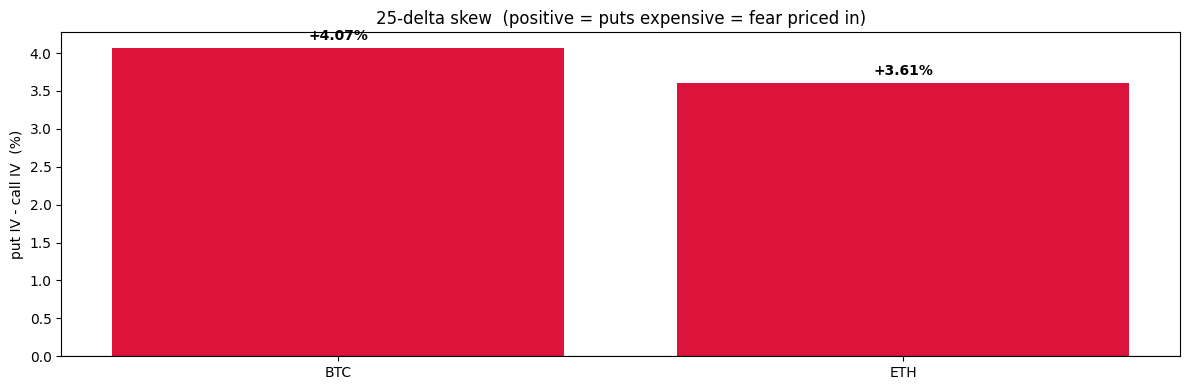


Skew interpretation:
  BTC    +4.07%  -> puts expensive (downside priced in)
  ETH    +3.61%  -> puts expensive (downside priced in)


In [38]:
def bs_delta(S, K, T, sigma, kind):
    if T <= 0 or sigma <= 0: return None
    d1 = (np.log(S/K) + 0.5*sigma**2 * T) / (sigma * np.sqrt(T))
    from scipy.stats import norm
    return float(norm.cdf(d1)) if kind == 'C' else float(norm.cdf(d1) - 1)

try:
    from scipy.stats import norm
    df['delta'] = [
        bs_delta(spots.get(r.underlying, 0), r.strike, r.days/365, r.iv_dec, r.kind)
        if pd.notna(r.iv_dec) and r.days > 0 else None
        for r in df.itertuples()
    ]
except ImportError:
    print('scipy not installed - skipping skew. pip install scipy')
    df['delta'] = None

skews = {}
for cur in pcr.coin:
    s = df[(df.underlying == cur) & df.delta.notna() & df.days.between(15, 45)]
    if len(s) == 0: continue
    c = s[s.kind=='C'].sort_values('delta')
    p = s[s.kind=='P'].sort_values('delta')
    if len(c) == 0 or len(p) == 0: continue
    c25 = c.iloc[(c.delta - 0.25).abs().argsort()[:1]]
    p25 = p.iloc[(p.delta + 0.25).abs().argsort()[:1]]
    sk = float(p25.iv_dec.iloc[0] - c25.iv_dec.iloc[0])
    skews[cur] = sk

if skews:
    fig, ax = plt.subplots(figsize=(12, 4))
    coins_list = list(skews.keys())
    vals = [skews[c]*100 for c in coins_list]
    colors = ['crimson' if v > 0 else 'seagreen' for v in vals]
    bars = ax.bar(coins_list, vals, color=colors)
    ax.axhline(0, color='black', lw=0.8)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + (0.1 if v >= 0 else -0.3),
                f'{v:+.2f}%', ha='center', fontsize=10, fontweight='bold')
    ax.set_title('25-delta skew  (positive = puts expensive = fear priced in)')
    ax.set_ylabel('put IV - call IV  (%)')
    plt.tight_layout(); plt.show()

    print('\nSkew interpretation:')
    for cur, sk in skews.items():
        if sk > 0.02:
            print(f'  {cur:<5}  {sk*100:+.2f}%  -> puts expensive (downside priced in)')
        elif sk < -0.02:
            print(f'  {cur:<5}  {sk*100:+.2f}%  -> calls expensive (upside chase)')
        else:
            print(f'  {cur:<5}  {sk*100:+.2f}%  -> balanced')

## 11. Composite sentiment score

Combines PCR(OI), PCR(volume), and skew into one score per coin.

**What this tells you:**

- **Score > 0.6** → strong call setup
- **Score < -0.6** → strong put setup
- **-0.3 to 0.3** → no edge

coin  pcr_oi  skew_%  divergence  score   action
 BTC   0.597    4.07       0.397 -0.806 BUY PUTS
 ETH   0.493    3.61       0.334 -0.850 BUY PUTS


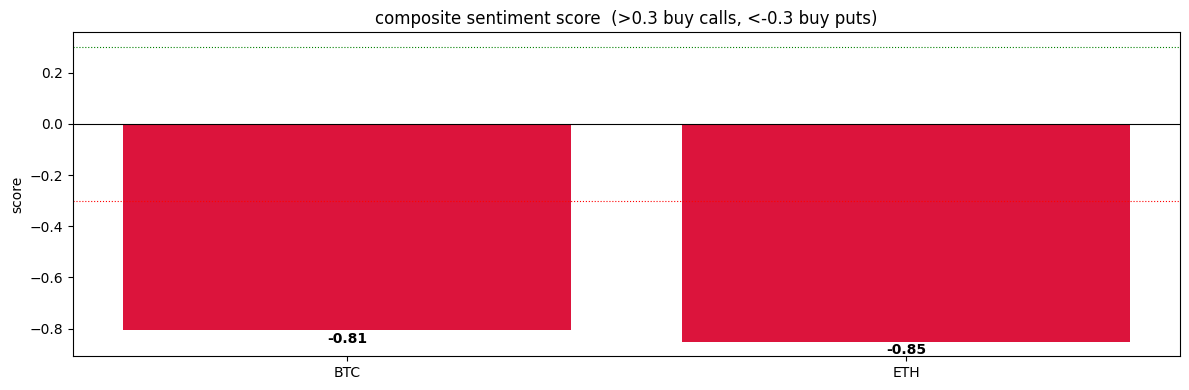

In [39]:
composite = []
for _, r in pcr.iterrows():
    coin = r['coin']
    # PCR based score: higher PCR = more fearful = bullish (contrarian)
    pcr_score = max(-1.0, min(1.0, (r['pcr_oi'] - 1.0) * 2))
    # Skew: negative skew (calls expensive) = too much greed = bearish
    skew_val = skews.get(coin, 0)
    skew_score = -max(-1.0, min(1.0, skew_val * 20))
    # Volume/OI divergence: fresh bearish flow = bearish
    div = r['pcr_vol'] - r['pcr_oi']
    div_score = -max(-1.0, min(1.0, div * 2))
    # combined
    combined = 0.5 * pcr_score + 0.3 * skew_score + 0.2 * div_score
    composite.append({
        'coin': coin,
        'pcr_oi': r['pcr_oi'],
        'skew_%': skew_val * 100,
        'divergence': div,
        'score': combined,
    })

comp = pd.DataFrame(composite).sort_values('score', ascending=False)
comp['action'] = comp.score.map(
    lambda s: 'BUY CALLS' if s > 0.3 else ('BUY PUTS' if s < -0.3 else 'WAIT'))
print(comp.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 4))
colors = ['seagreen' if s > 0 else 'crimson' for s in comp.score]
bars = ax.bar(comp.coin, comp.score, color=colors)
ax.axhline(0, color='black', lw=0.8)
ax.axhline(0.3, ls=':', color='green', lw=0.8)
ax.axhline(-0.3, ls=':', color='red', lw=0.8)
for b, v in zip(bars, comp.score):
    ax.text(b.get_x() + b.get_width()/2, v + (0.02 if v >= 0 else -0.05),
            f'{v:+.2f}', ha='center', fontsize=10, fontweight='bold')
ax.set_title('composite sentiment score  (>0.3 buy calls, <-0.3 buy puts)')
ax.set_ylabel('score')
plt.tight_layout(); plt.show()

## 12. Final recommendations

Each coin gets one clear action based on the composite score.

In [40]:
print('=' * 72)
print('FINAL PCR RECOMMENDATIONS')
print('=' * 72)
print()
for _, r in comp.iterrows():
    print(f"{r['coin']:<5}  "
          f"PCR={r['pcr_oi']:.2f}  "
          f"skew={r['skew_%']:+.1f}%  "
          f"flow_div={r['divergence']:+.2f}  "
          f"-> {r['action']}")

print()
print('=' * 72)
print('EXTREMES')
print('=' * 72)
best_call = comp.iloc[0]
best_put  = comp.iloc[-1]
print(f"\n  Strongest CALL setup: {best_call['coin']}  (score {best_call['score']:+.2f})")
print(f"  Strongest PUT setup : {best_put['coin']}   (score {best_put['score']:+.2f})")
print()
print('Next steps:')
print('  - For chosen coin, run 01_options_buyer_analysis for exact contract')
print('  - Check futures positioning in 02_futures_analysis')
print('  - Check timing in best_next_time_to_trede')

FINAL PCR RECOMMENDATIONS

BTC    PCR=0.60  skew=+4.1%  flow_div=+0.40  -> BUY PUTS
ETH    PCR=0.49  skew=+3.6%  flow_div=+0.33  -> BUY PUTS

EXTREMES

  Strongest CALL setup: BTC  (score -0.81)
  Strongest PUT setup : ETH   (score -0.85)

Next steps:
  - For chosen coin, run 01_options_buyer_analysis for exact contract
  - Check futures positioning in 02_futures_analysis
  - Check timing in best_next_time_to_trede


PCR by moneyness bucket


In [41]:
# PCR by moneyness bucket (OTM puts / ATM / OTM calls)
for cur in pcr.coin:
    s = df[(df.underlying == cur) & (df.days.between(7, 90))].copy()
    if len(s) == 0: continue
    spot = spots[cur]
    s['moneyness'] = (s.strike - spot) / spot * 100

    def bucket(m):
        if m < -15: return 'deep OTM puts'
        if m < -5:  return 'OTM puts'
        if m <= 5:  return 'ATM'
        if m <= 15: return 'OTM calls'
        return 'deep OTM calls'

    s['bucket'] = s.moneyness.map(bucket)
    b = s.groupby(['bucket', 'kind']).oi.sum().unstack('kind').fillna(0)
    print(f'\n{cur}:')
    print(b.to_string())


BTC:
kind                  C        P
bucket                          
ATM             17833.2  12809.9
OTM calls       32357.5   2552.8
OTM puts         5970.4  16851.2
deep OTM calls  53222.3    843.9
deep OTM puts    4894.3  37314.6

ETH:
kind                   C         P
bucket                            
ATM             104330.0   54979.0
OTM calls        69844.0   15240.0
OTM puts         12287.0   37559.0
deep OTM calls  384966.0   19604.0
deep OTM puts     8725.0  109507.0


Moneyness distribution chart

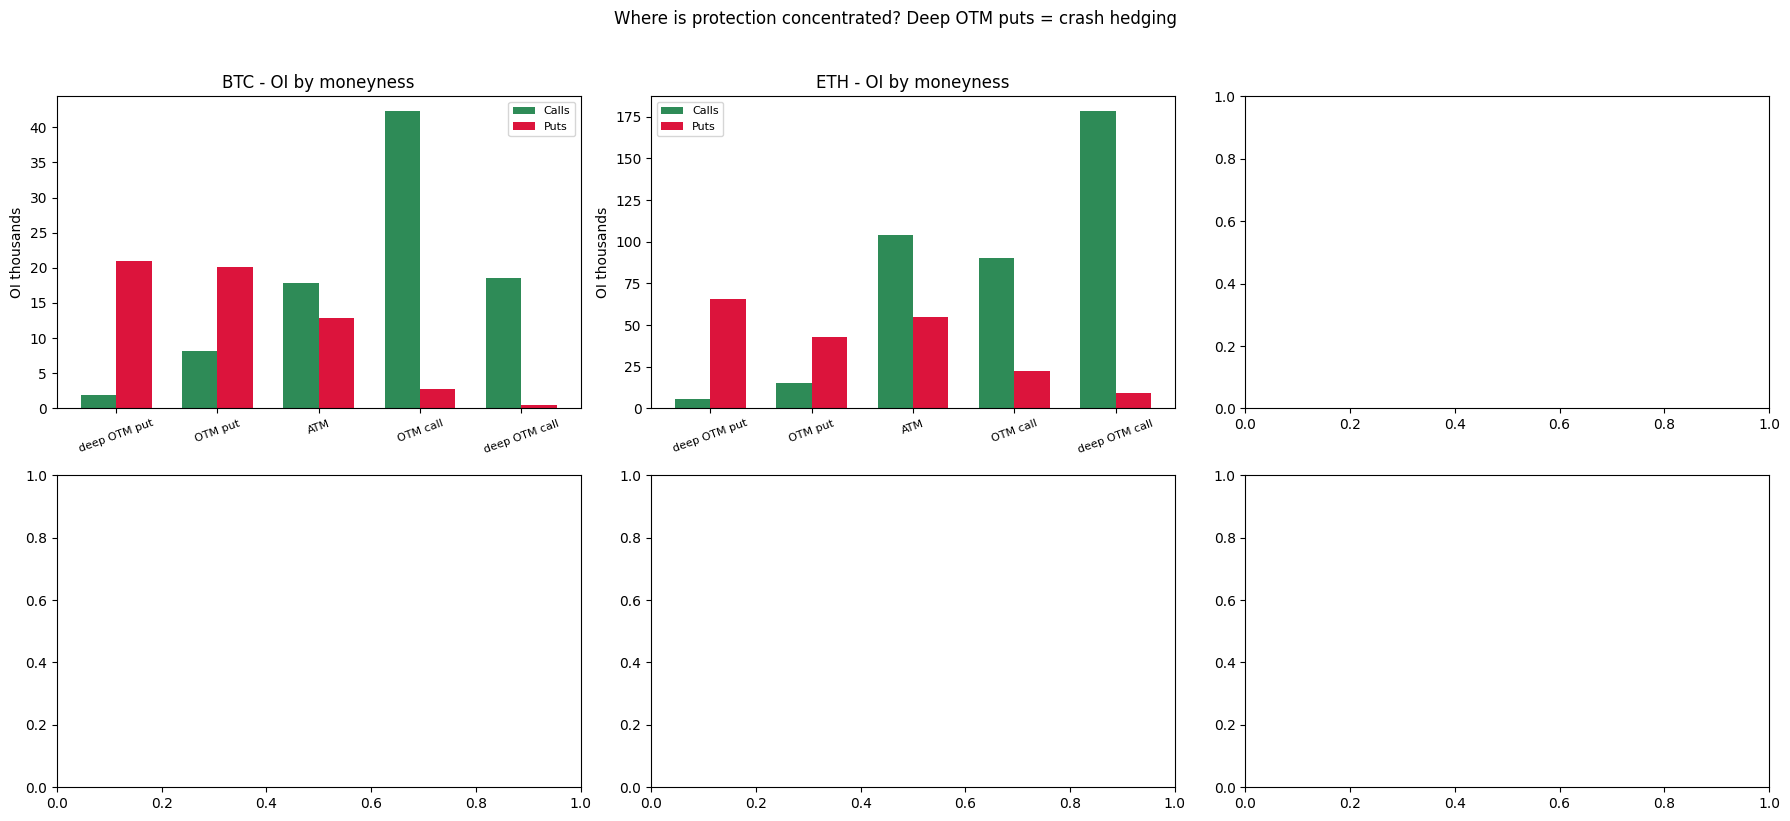

In [42]:
# PCR by moneyness bucket - where is protection concentrated?
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
axes = axes.flatten()

for i, cur in enumerate(pcr.coin):
    s = df[(df.underlying == cur) & (df.days.between(7, 90))].copy()
    if len(s) == 0:
        axes[i].axis('off')
        continue
    spot = spots[cur]
    s['moneyness'] = (s.strike - spot) / spot * 100
    s = s[s.moneyness.between(-40, 40)]

    def bucket(m):
        if m < -20: return 'deep OTM put'
        if m < -5:  return 'OTM put'
        if m <= 5:  return 'ATM'
        if m <= 20: return 'OTM call'
        return 'deep OTM call'

    s['bucket'] = s.moneyness.map(bucket)
    b = s.groupby(['bucket', 'kind']).oi.sum().unstack('kind').fillna(0)
    order = ['deep OTM put', 'OTM put', 'ATM', 'OTM call', 'deep OTM call']
    b = b.reindex(order)

    x = np.arange(len(b))
    w = 0.35
    axes[i].bar(x - w/2, b.get('C', 0) / 1e3, w, label='Calls', color='seagreen')
    axes[i].bar(x + w/2, b.get('P', 0) / 1e3, w, label='Puts',  color='crimson')
    axes[i].set_xticks(x)
    axes[i].set_xticklabels(b.index, rotation=20, fontsize=8)
    axes[i].set_title(f'{cur} - OI by moneyness')
    axes[i].set_ylabel('OI thousands')
    axes[i].legend(fontsize=8)

plt.suptitle('Where is protection concentrated? Deep OTM puts = crash hedging', y=1.02)
plt.tight_layout(); plt.show()

PCR summary with gauge dials


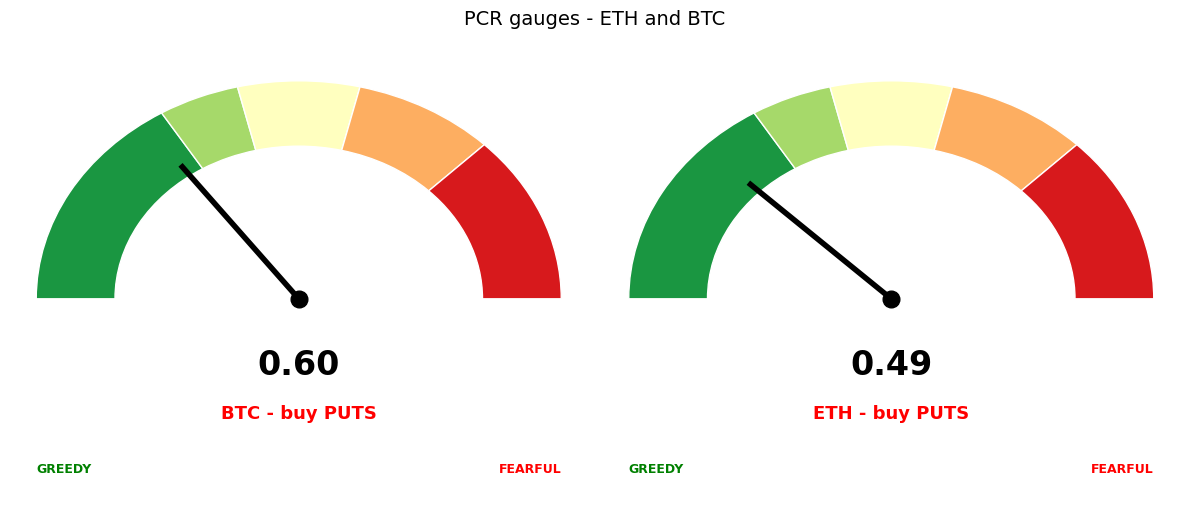

In [43]:
# ETH + BTC PCR with gauge dials
TARGETS = ['BTC', 'ETH']
active = [c for c in TARGETS if c in pcr.coin.values]

fig, axes = plt.subplots(1, len(active), figsize=(6 * len(active), 5))
if len(active) == 1: axes = [axes]

for ax, cur in zip(axes, active):
    r = pcr[pcr.coin == cur].iloc[0]
    ratio = r['pcr_oi']

    # gauge zones
    zones = [(0.0, 0.65, '#1a9641', 'greedy'), (0.65, 0.85, '#a6d96a', ''),
             (0.85, 1.15, '#ffffbf', 'neutral'), (1.15, 1.5, '#fdae61', ''),
             (1.5, 2.0, '#d7191c', 'fearful')]
    for lo, hi, color, _ in zones:
        t1 = 180 - (hi / 2.0) * 180
        t2 = 180 - (lo / 2.0) * 180
        ax.add_patch(plt.matplotlib.patches.Wedge(
            (0, 0), 1, t1, t2, width=0.3, facecolor=color, edgecolor='white'))

    clamped = min(ratio, 2.0)
    theta = np.pi * (1 - clamped / 2.0)
    ax.plot([0, np.cos(theta) * 0.75], [0, np.sin(theta) * 0.75], 'k-', lw=4)
    ax.plot(0, 0, 'ko', ms=12)
    ax.text(0, -0.35, f'{ratio:.2f}', ha='center', fontsize=24, fontweight='bold')
    ax.text(0, -0.55, f'{cur} - {r["action"]}', ha='center', fontsize=13, fontweight='bold',
            color='green' if 'CALL' in r['action'] else ('red' if 'PUT' in r['action'] else 'black'))
    ax.text(-1.0, -0.8, 'GREEDY', ha='left', fontsize=9, color='green', fontweight='bold')
    ax.text(1.0, -0.8, 'FEARFUL', ha='right', fontsize=9, color='red', fontweight='bold')
    ax.set_xlim(-1.1, 1.1); ax.set_ylim(-0.9, 1.1)
    ax.axis('off')

plt.suptitle('PCR gauges - ETH and BTC', fontsize=14, y=1.0)
plt.tight_layout(); plt.show()

OI breakdown (calls vs puts bars)


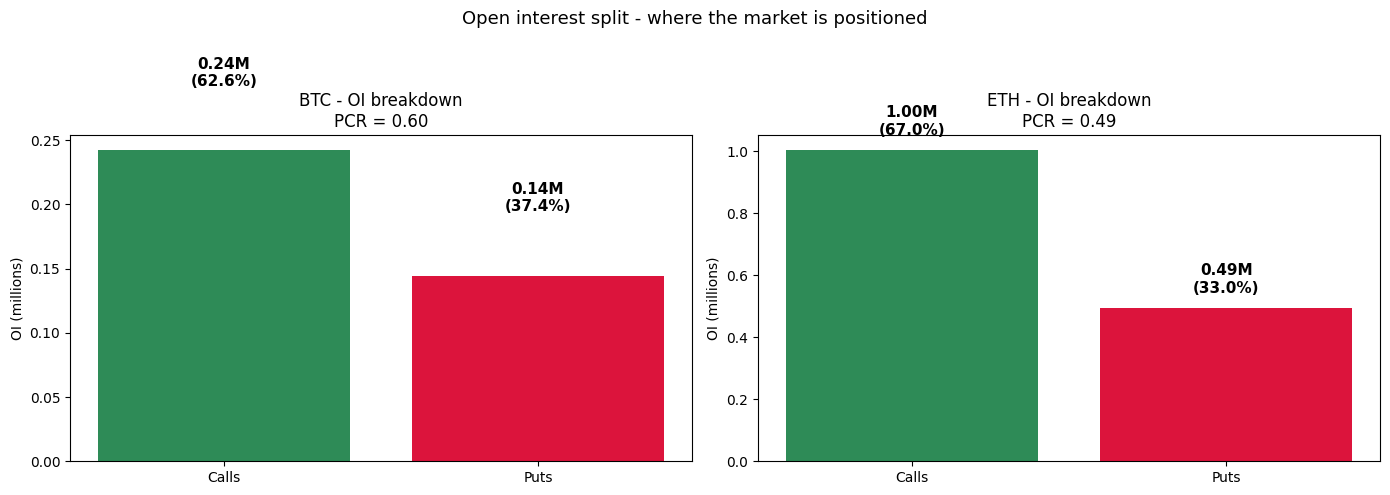

In [44]:
# OI breakdown bars - which side dominates
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, cur in zip(axes, active):
    r = pcr[pcr.coin == cur].iloc[0]
    calls = r['call_oi']
    puts  = r['put_oi']
    total = calls + puts

    ax.bar(['Calls', 'Puts'], [calls / 1e6, puts / 1e6],
           color=['seagreen', 'crimson'])
    ax.set_title(f'{cur} - OI breakdown\nPCR = {r["pcr_oi"]:.2f}', fontsize=12)
    ax.set_ylabel('OI (millions)')

    for i, v in enumerate([calls, puts]):
        pct = v / total * 100
        ax.text(i, v / 1e6 + 0.05, f'{v/1e6:.2f}M\n({pct:.1f}%)',
                ha='center', fontsize=11, fontweight='bold')

plt.suptitle('Open interest split - where the market is positioned', fontsize=13)
plt.tight_layout(); plt.show()

Volume vs OI divergence

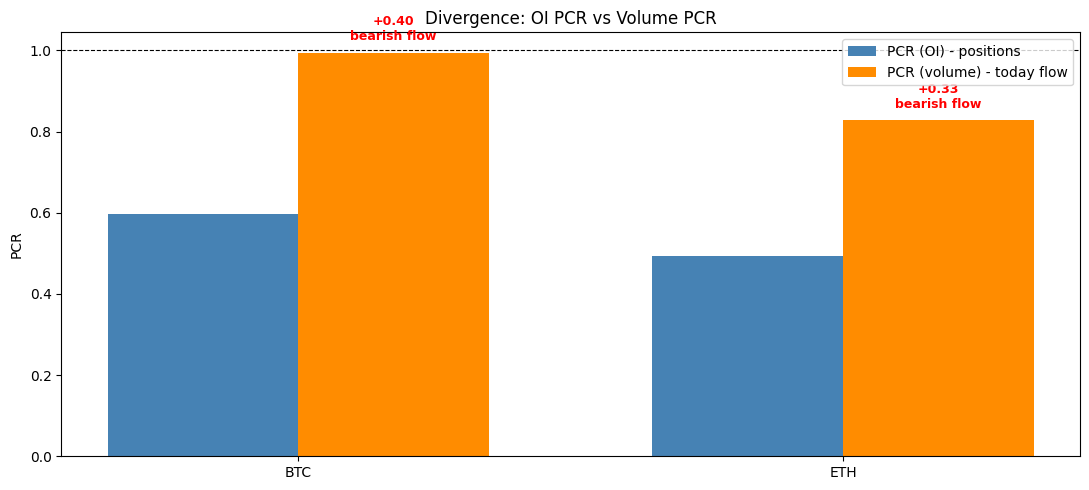


Divergence analysis:
  BTC    vol PCR +0.40 higher -> today's flow is BEARISH (early reversal)
  ETH    vol PCR +0.33 higher -> today's flow is BEARISH (early reversal)


In [45]:
# Volume PCR vs OI PCR - is today's flow different from positions?
fig, ax = plt.subplots(figsize=(11, 5))

x = np.arange(len(active))
w = 0.35

oi_vals = [pcr[pcr.coin == c].iloc[0]['pcr_oi'] for c in active]
vol_vals = [pcr[pcr.coin == c].iloc[0]['pcr_vol'] for c in active]

ax.bar(x - w/2, oi_vals,  w, label='PCR (OI) - positions', color='steelblue')
ax.bar(x + w/2, vol_vals, w, label='PCR (volume) - today flow', color='darkorange')
ax.axhline(1.0, color='black', lw=0.8, ls='--')
ax.set_xticks(x); ax.set_xticklabels(active)
ax.set_ylabel('PCR')
ax.set_title('Divergence: OI PCR vs Volume PCR')
ax.legend()

for i, (o, v) in enumerate(zip(oi_vals, vol_vals)):
    div = v - o
    if abs(div) > 0.15:
        color = 'red' if div > 0 else 'green'
        ax.annotate(f'{div:+.2f}\n{"bearish flow" if div > 0 else "bullish flow"}',
                    (i + w/2, v + 0.03), ha='center', fontsize=9,
                    color=color, fontweight='bold')

plt.tight_layout(); plt.show()

print('\nDivergence analysis:')
for cur, o, v in zip(active, oi_vals, vol_vals):
    div = v - o
    if div > 0.15:
        print(f'  {cur:<5}  vol PCR {div:+.2f} higher -> today\'s flow is BEARISH (early reversal)')
    elif div < -0.15:
        print(f'  {cur:<5}  vol PCR {div:+.2f} lower  -> today\'s flow is BULLISH (early momentum)')
    else:
        print(f'  {cur:<5}  vol PCR {div:+.2f}     -> OI and volume agree')

OI by strike (walls)


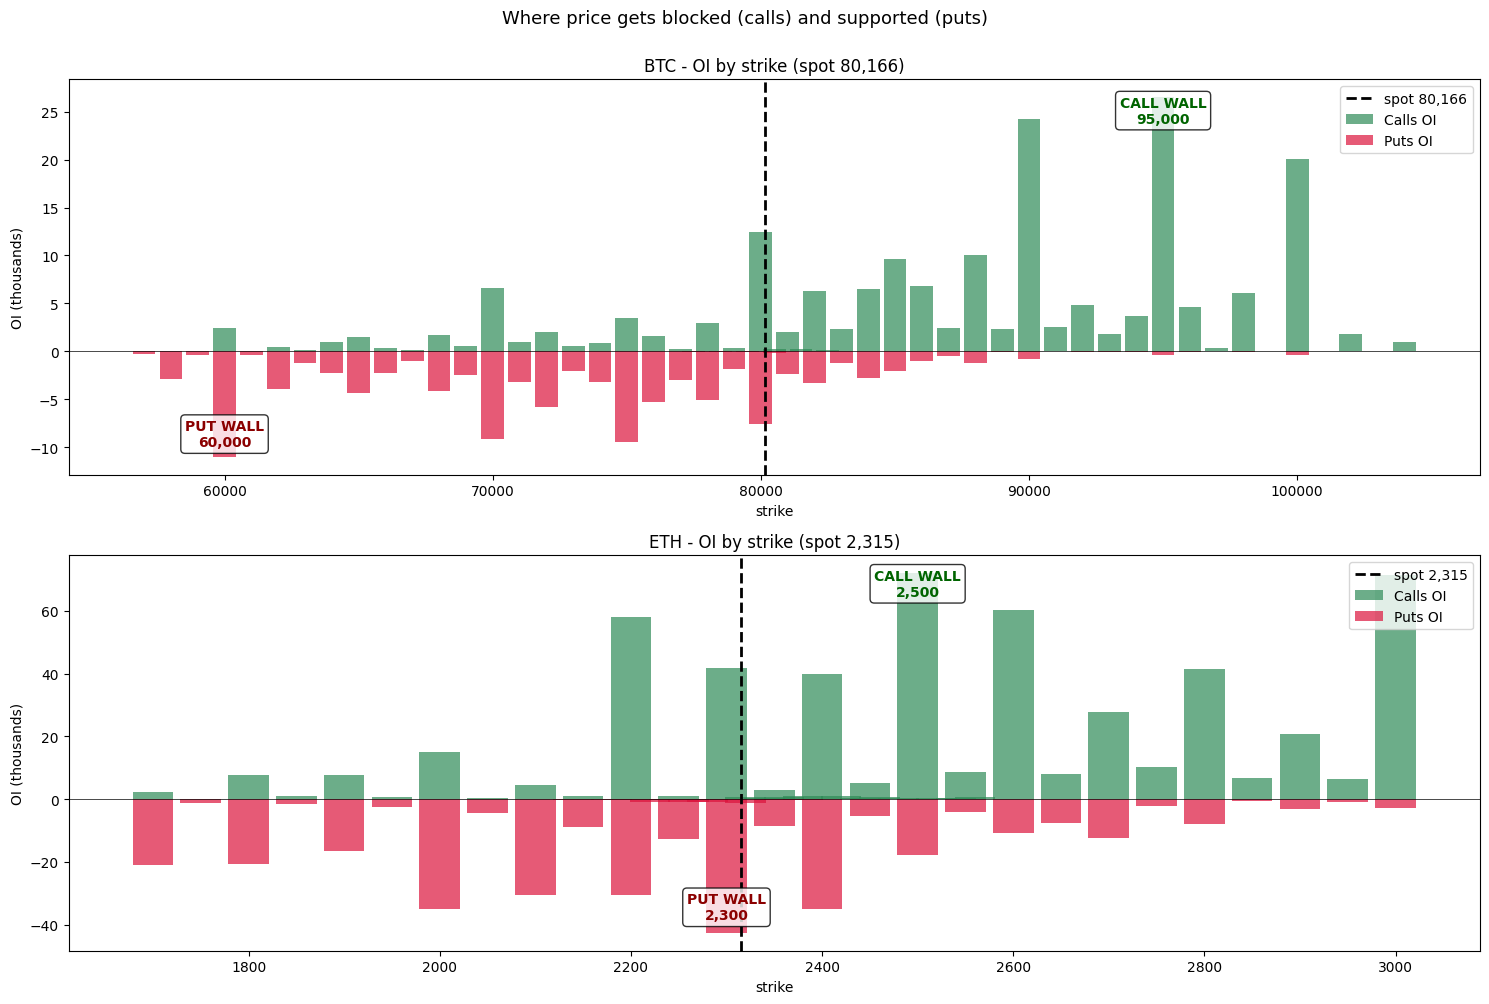

In [46]:
# OI by strike for ETH and BTC - where price gets pinned
fig, axes = plt.subplots(2, 1, figsize=(15, 10))

for ax, cur in zip(axes, active):
    s = df[df.underlying == cur]
    spot = spots[cur]
    # limit to strikes near spot
    s_near = s[(s.strike > spot * 0.7) & (s.strike < spot * 1.3)]
    pivot = s_near.pivot_table(index='strike', columns='kind',
                                values='oi', aggfunc='sum').fillna(0)

    if len(pivot) == 0:
        ax.axis('off'); continue

    x = pivot.index
    width = (x[1] - x[0]) * 0.85 if len(x) > 1 else 100

    ax.bar(x, pivot['C'] / 1e3, width, color='seagreen', alpha=0.7, label='Calls OI')
    ax.bar(x, -pivot['P'] / 1e3, width, color='crimson', alpha=0.7, label='Puts OI')
    ax.axvline(spot, color='black', lw=2, ls='--', label=f'spot {spot:,.0f}')
    ax.axhline(0, color='black', lw=0.5)

    # annotate walls
    call_wall = pivot['C'].idxmax()
    put_wall  = pivot['P'].idxmax()
    ax.text(call_wall, pivot['C'].max() / 1e3 * 0.9, f'CALL WALL\n{call_wall:,.0f}',
            ha='center', color='darkgreen', fontsize=10, fontweight='bold',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    ax.text(put_wall, -pivot['P'].max() / 1e3 * 0.9, f'PUT WALL\n{put_wall:,.0f}',
            ha='center', color='darkred', fontsize=10, fontweight='bold',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    ax.set_title(f'{cur} - OI by strike (spot {spot:,.0f})', fontsize=12)
    ax.set_xlabel('strike'); ax.set_ylabel('OI (thousands)')
    ax.legend(loc='upper right')

plt.suptitle('Where price gets blocked (calls) and supported (puts)', fontsize=13, y=1.0)
plt.tight_layout(); plt.show()

Max pain curve


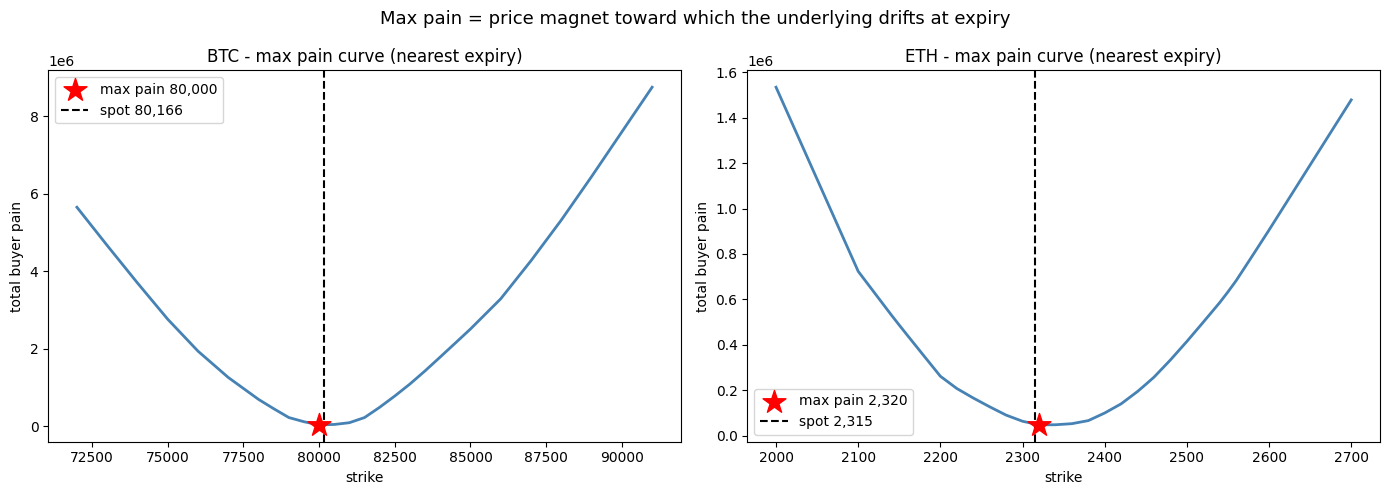


Max pain summary:
  BTC    max pain     80,000  (spot     80,166, -0.2%)
  ETH    max pain      2,320  (spot      2,315, +0.2%)


In [47]:
# Max pain for ETH and BTC
def max_pain_full(currency):
    s = df[df.underlying == currency]
    if len(s) == 0: return None
    sub = s[s.expiry == s.expiry.min()]
    if len(sub) == 0: return None
    strikes = sorted(sub.strike.unique())
    pains = {}
    for K in strikes:
        pain = 0.0
        for _, r in sub.iterrows():
            oi = r.oi or 0
            if r.kind == 'C': pain += oi * max(0.0, K - r.strike)
            else:            pain += oi * max(0.0, r.strike - K)
        pains[K] = pain
    return pains

fig, axes = plt.subplots(1, len(active), figsize=(7 * len(active), 5))
if len(active) == 1: axes = [axes]

for ax, cur in zip(axes, active):
    pains = max_pain_full(cur)
    if pains is None:
        ax.axis('off'); continue

    strikes = list(pains.keys())
    values = list(pains.values())
    mp = strikes[values.index(min(values))]

    ax.plot(strikes, values, lw=2, color='steelblue')
    ax.scatter([mp], [min(values)], color='red', s=300, marker='*', zorder=5,
               label=f'max pain {mp:,.0f}')
    ax.axvline(spots[cur], color='black', ls='--', lw=1.5, label=f'spot {spots[cur]:,.0f}')
    ax.set_title(f'{cur} - max pain curve (nearest expiry)')
    ax.set_xlabel('strike'); ax.set_ylabel('total buyer pain')
    ax.legend()

plt.suptitle('Max pain = price magnet toward which the underlying drifts at expiry', fontsize=13)
plt.tight_layout(); plt.show()

print('\nMax pain summary:')
for cur in active:
    pains = max_pain_full(cur)
    if pains is not None:
        mp = min(pains, key=pains.get)
        dist = (mp - spots[cur]) / spots[cur] * 100
        print(f'  {cur:<5}  max pain {mp:>10,.0f}  (spot {spots[cur]:>10,.0f}, {dist:+.1f}%)')
        if dist > 1:
            print(f'         -> price expected to RISE toward max pain -> buy CALLS')
        elif dist < -1:
            print(f'         -> price expected to FALL toward max pain -> buy PUTS')

Put vs Call IV by strike


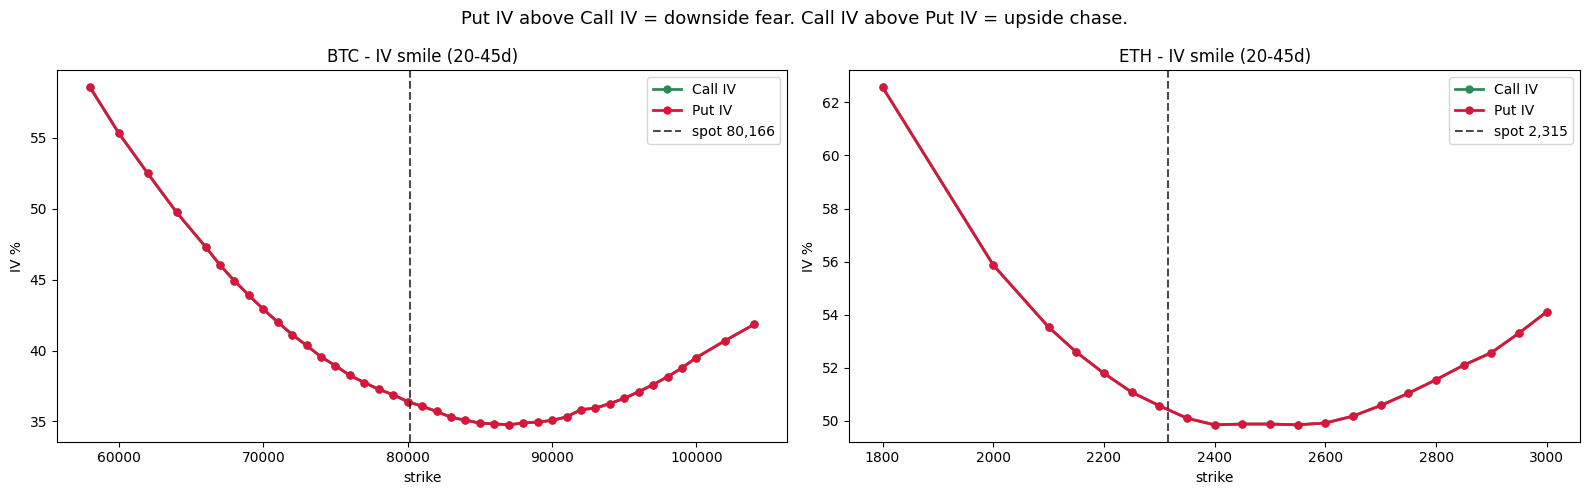

In [48]:
# Put vs Call IV by strike - the skew visual
fig, axes = plt.subplots(1, len(active), figsize=(8 * len(active), 5))
if len(active) == 1: axes = [axes]

for ax, cur in zip(axes, active):
    s = df[(df.underlying == cur) & (df.days.between(20, 45)) & df.iv_dec.notna()].copy()
    if len(s) == 0:
        ax.axis('off'); continue

    spot = spots[cur]
    s = s[(s.strike > spot * 0.7) & (s.strike < spot * 1.3)]
    pivot = s.pivot_table(index='strike', columns='kind', values='iv_dec')

    if 'C' in pivot.columns:
        ax.plot(pivot.index, pivot['C'] * 100, marker='o', ms=5, lw=2,
                label='Call IV', color='seagreen')
    if 'P' in pivot.columns:
        ax.plot(pivot.index, pivot['P'] * 100, marker='o', ms=5, lw=2,
                label='Put IV', color='crimson')

    ax.axvline(spot, color='black', ls='--', lw=1.5, alpha=0.7, label=f'spot {spot:,.0f}')
    ax.set_title(f'{cur} - IV smile (20-45d)')
    ax.set_xlabel('strike'); ax.set_ylabel('IV %')
    ax.legend()

plt.suptitle('Put IV above Call IV = downside fear. Call IV above Put IV = upside chase.', fontsize=13)
plt.tight_layout(); plt.show()

IV term structure (near vs far)


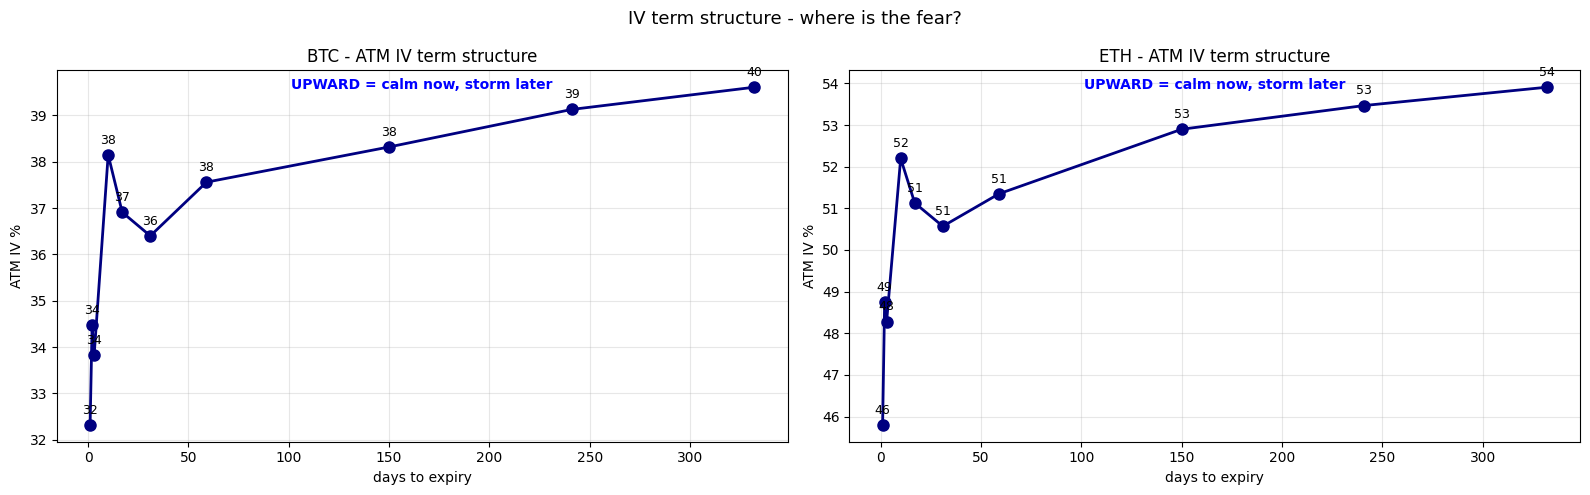

In [49]:
# Term structure - is fear concentrated near-term or long-term?
fig, axes = plt.subplots(1, len(active), figsize=(8 * len(active), 5))
if len(active) == 1: axes = [axes]

for ax, cur in zip(axes, active):
    s = df[df.underlying == cur].copy()
    spot = spots[cur]
    rows = []
    for exp, g in s.groupby('expiry'):
        atm = g.iloc[(g.strike - spot).abs().argsort()[:1]]
        if len(atm) and pd.notna(atm.iv_dec.iloc[0]):
            rows.append({'days': int(atm.days.iloc[0]),
                         'atm_iv': float(atm.iv_dec.iloc[0]) * 100})
    ts = pd.DataFrame(rows).sort_values('days')
    ts = ts[ts.days.between(1, 365)]

    if len(ts) == 0:
        ax.axis('off'); continue

    ax.plot(ts.days, ts.atm_iv, marker='o', lw=2, color='navy', ms=8)
    ax.set_title(f'{cur} - ATM IV term structure')
    ax.set_xlabel('days to expiry'); ax.set_ylabel('ATM IV %')
    ax.grid(alpha=0.3)

    for d, v in zip(ts.days, ts.atm_iv):
        ax.annotate(f'{v:.0f}', (d, v), textcoords='offset points',
                    xytext=(0, 8), ha='center', fontsize=9)

    if ts.atm_iv.iloc[0] > ts.atm_iv.iloc[-1] * 1.1:
        ax.text(0.5, 0.95, 'INVERTED = near-term panic',
                transform=ax.transAxes, ha='center', color='red',
                fontsize=10, fontweight='bold')
    elif ts.atm_iv.iloc[-1] > ts.atm_iv.iloc[0] * 1.1:
        ax.text(0.5, 0.95, 'UPWARD = calm now, storm later',
                transform=ax.transAxes, ha='center', color='blue',
                fontsize=10, fontweight='bold')

plt.suptitle('IV term structure - where is the fear?', fontsize=13)
plt.tight_layout(); plt.show()

IV rank per coin


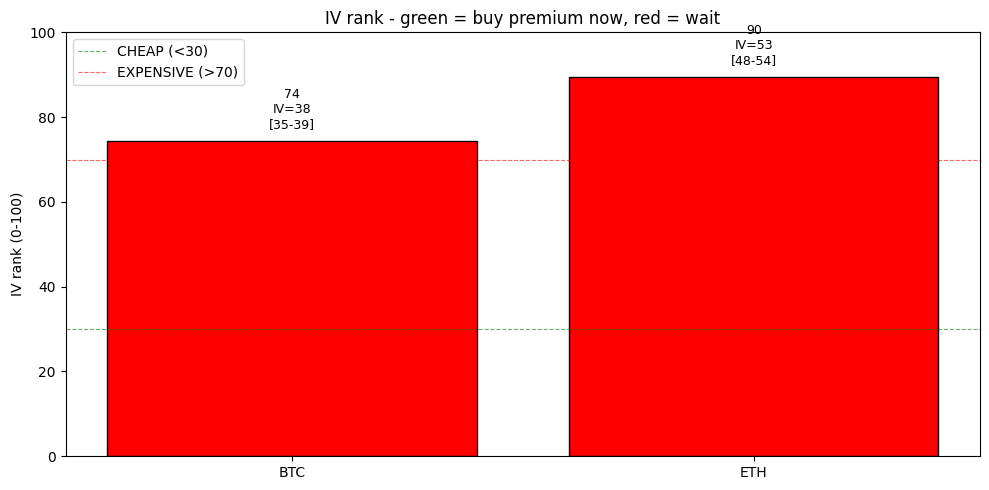


IV rank summary:
  BTC    IV=38.0  rank=74/100  [EXPENSIVE - wait]  range [34.8, 39.1]
  ETH    IV=53.0  rank=90/100  [EXPENSIVE - wait]  range [47.5, 53.6]


In [50]:
# IV rank - is premium cheap or expensive today?
def fetch_iv_index(currency, days=30):
    end = int(time.time() * 1000)
    start = end - days * 86_400_000
    try:
        r = requests.get(f'{DERIBIT}/get_volatility_index_data',
                         params={'currency': currency, 'start_timestamp': start,
                                 'end_timestamp': end, 'resolution': '1D'}, timeout=15)
        r.raise_for_status()
        return [x[4] for x in r.json()['result']['data']]
    except:
        return []

fig, ax = plt.subplots(figsize=(10, 5))
coins_list, iv_ranks, current_ivs, min_ivs, max_ivs = [], [], [], [], []

for cur in active:
    vals = fetch_iv_index(cur)
    if len(vals) < 5:
        print(f'{cur}: no IV index')
        continue
    cur_iv = vals[-1]
    lo, hi = min(vals), max(vals)
    rank = (cur_iv - lo) / (hi - lo) * 100 if hi > lo else 50
    coins_list.append(cur)
    iv_ranks.append(rank)
    current_ivs.append(cur_iv)
    min_ivs.append(lo)
    max_ivs.append(hi)

colors = ['green' if r < 30 else ('gold' if r < 60 else 'red') for r in iv_ranks]
bars = ax.bar(coins_list, iv_ranks, color=colors, edgecolor='black')
ax.axhline(30, color='green', ls='--', lw=0.8, alpha=0.6, label='CHEAP (<30)')
ax.axhline(70, color='red',   ls='--', lw=0.8, alpha=0.6, label='EXPENSIVE (>70)')
ax.set_ylim(0, 100)
ax.set_ylabel('IV rank (0-100)')
ax.set_title('IV rank - green = buy premium now, red = wait')

for b, r, cv, mn, mx in zip(bars, iv_ranks, current_ivs, min_ivs, max_ivs):
    ax.text(b.get_x() + b.get_width()/2, r + 3,
            f'{r:.0f}\nIV={cv:.0f}\n[{mn:.0f}-{mx:.0f}]',
            ha='center', fontsize=9)

ax.legend()
plt.tight_layout(); plt.show()

print('\nIV rank summary:')
for cur, r, cv, mn, mx in zip(coins_list, iv_ranks, current_ivs, min_ivs, max_ivs):
    label = 'CHEAP - good to buy' if r < 30 else ('NEUTRAL' if r < 60 else 'EXPENSIVE - wait')
    print(f'  {cur:<5}  IV={cv:.1f}  rank={r:.0f}/100  [{label}]  range [{mn:.1f}, {mx:.1f}]')

Sentiment heatmap (PCR × IV rank)


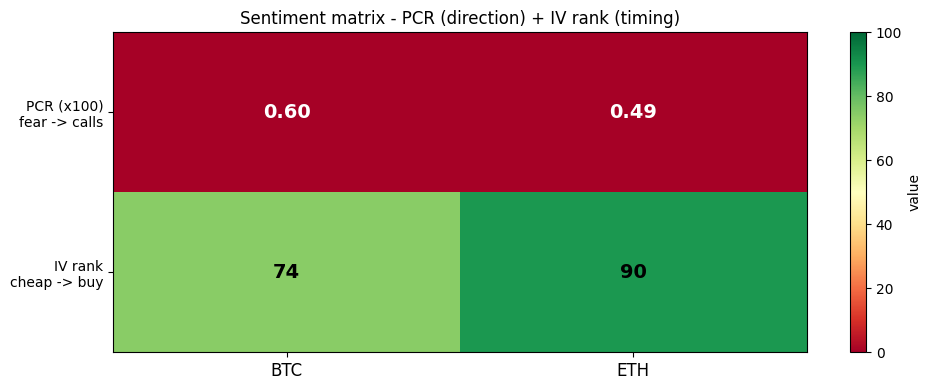

In [51]:
# Heatmap combining PCR (direction) and IV rank (timing)
matrix = []
for cur in active:
    r = pcr[pcr.coin == cur].iloc[0]
    vals = fetch_iv_index(cur)
    if len(vals) < 5: iv_rank = 50
    else:
        lo, hi = min(vals), max(vals)
        iv_rank = (vals[-1] - lo) / (hi - lo) * 100 if hi > lo else 50

    matrix.append({
        'coin': cur,
        'pcr': r['pcr_oi'],
        'iv_rank': iv_rank,
        'signal': (r['pcr_oi'] - 1.0) * 2 + (50 - iv_rank) / 100,
    })

m = pd.DataFrame(matrix).set_index('coin')

fig, ax = plt.subplots(figsize=(10, 4))
data = m[['pcr', 'iv_rank']].values
im = ax.imshow(data.T, cmap='RdYlGn', aspect='auto',
               vmin=0, vmax=100)
ax.set_xticks(range(len(m)))
ax.set_xticklabels(m.index, fontsize=12)
ax.set_yticks([0, 1])
ax.set_yticklabels(['PCR (x100)\nfear -> calls', 'IV rank\ncheap -> buy'])

for i in range(len(m)):
    for j, label in enumerate(['PCR', 'IV rank']):
        val = data[i, j]
        txt = f'{val:.0f}' if label == 'IV rank' else f'{val:.2f}'
        ax.text(i, j, txt, ha='center', va='center',
                fontsize=14, fontweight='bold',
                color='white' if (label == 'PCR' and val < 50) else 'black')

plt.colorbar(im, ax=ax, label='value')
ax.set_title('Sentiment matrix - PCR (direction) + IV rank (timing)')
plt.tight_layout(); plt.show()

Complete decision dashboard

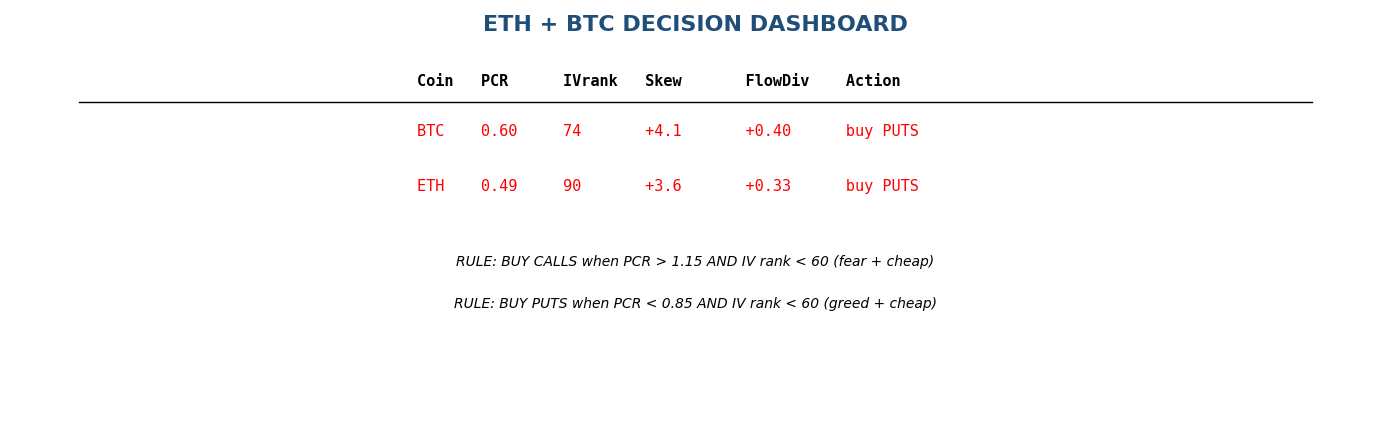

In [52]:
# Final dashboard - ETH and BTC only
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.axis('off')

ax.text(0.5, 0.95, 'ETH + BTC DECISION DASHBOARD',
        ha='center', fontsize=16, fontweight='bold',
        transform=ax.transAxes, color='#1F4E78')

header = f"{'Coin':<6} {'PCR':<8} {'IVrank':<8} {'Skew':<10} {'FlowDiv':<10} {'Action':<14}"
ax.text(0.5, 0.82, header, ha='center', family='monospace',
        fontsize=11, fontweight='bold', transform=ax.transAxes)
ax.plot([0.05, 0.95], [0.78, 0.78], color='black', lw=1, transform=ax.transAxes)

y = 0.70
for cur in active:
    r = pcr[pcr.coin == cur].iloc[0]
    vals = fetch_iv_index(cur)
    if len(vals) < 5: iv_rank = 50
    else:
        lo, hi = min(vals), max(vals)
        iv_rank = (vals[-1] - lo) / (hi - lo) * 100 if hi > lo else 50

    skew_val = skews.get(cur, 0) * 100
    div = r['pcr_vol'] - r['pcr_oi']
    action = r['action']
    color = 'green' if 'CALL' in action else ('red' if 'PUT' in action else 'black')

    line = f"{cur:<6} {r['pcr_oi']:<8.2f} {iv_rank:<8.0f} {skew_val:<+10.1f} {div:<+10.2f} {action:<14}"
    ax.text(0.5, y, line, ha='center', family='monospace', fontsize=11,
            color=color, transform=ax.transAxes)
    y -= 0.13

ax.text(0.5, y - 0.05,
        'RULE: BUY CALLS when PCR > 1.15 AND IV rank < 60 (fear + cheap)',
        ha='center', fontsize=10, style='italic', transform=ax.transAxes)
ax.text(0.5, y - 0.15,
        'RULE: BUY PUTS when PCR < 0.85 AND IV rank < 60 (greed + cheap)',
        ha='center', fontsize=10, style='italic', transform=ax.transAxes)
plt.tight_layout(); plt.show()

PCR history tracker


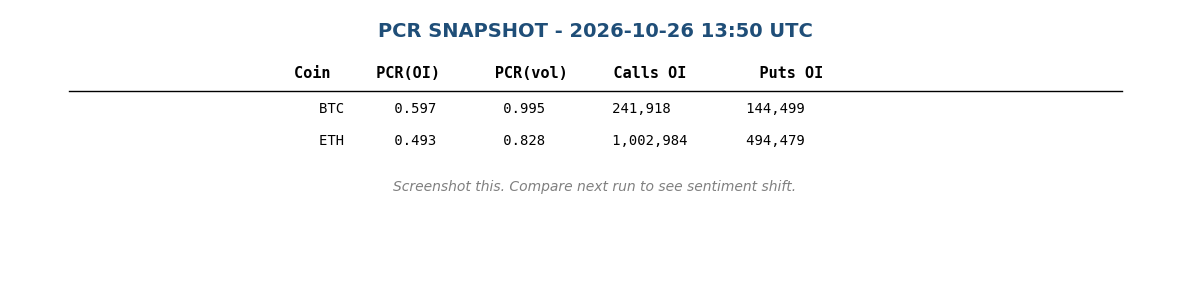

In [53]:
# Manual PCR tracker - save each run to build history
from datetime import datetime

fig, ax = plt.subplots(figsize=(12, 3))
ax.axis('off')

ax.text(0.5, 0.9, f'PCR SNAPSHOT - {datetime.now():%Y-%m-%d %H:%M UTC}',
        ha='center', fontsize=14, fontweight='bold',
        transform=ax.transAxes, color='#1F4E78')

header = f"{'Coin':<8} {'PCR(OI)':<12} {'PCR(vol)':<12} {'Calls OI':<15} {'Puts OI':<15}"
ax.text(0.5, 0.75, header, ha='center', family='monospace',
        fontsize=11, fontweight='bold', transform=ax.transAxes)
ax.plot([0.05, 0.95], [0.70, 0.70], color='black', lw=1, transform=ax.transAxes)

y = 0.62
for cur in active:
    r = pcr[pcr.coin == cur].iloc[0]
    line = f"{cur:<8} {r['pcr_oi']:<12.3f} {r['pcr_vol']:<12.3f} {r['call_oi']:<15,.0f} {r['put_oi']:<15,.0f}"
    ax.text(0.5, y, line, ha='center', family='monospace',
            fontsize=10, transform=ax.transAxes)
    y -= 0.12

ax.text(0.5, y - 0.05,
        'Screenshot this. Compare next run to see sentiment shift.',
        ha='center', fontsize=10, style='italic',
        color='gray', transform=ax.transAxes)
plt.tight_layout(); plt.show()

2-panel combined chart (the answer)

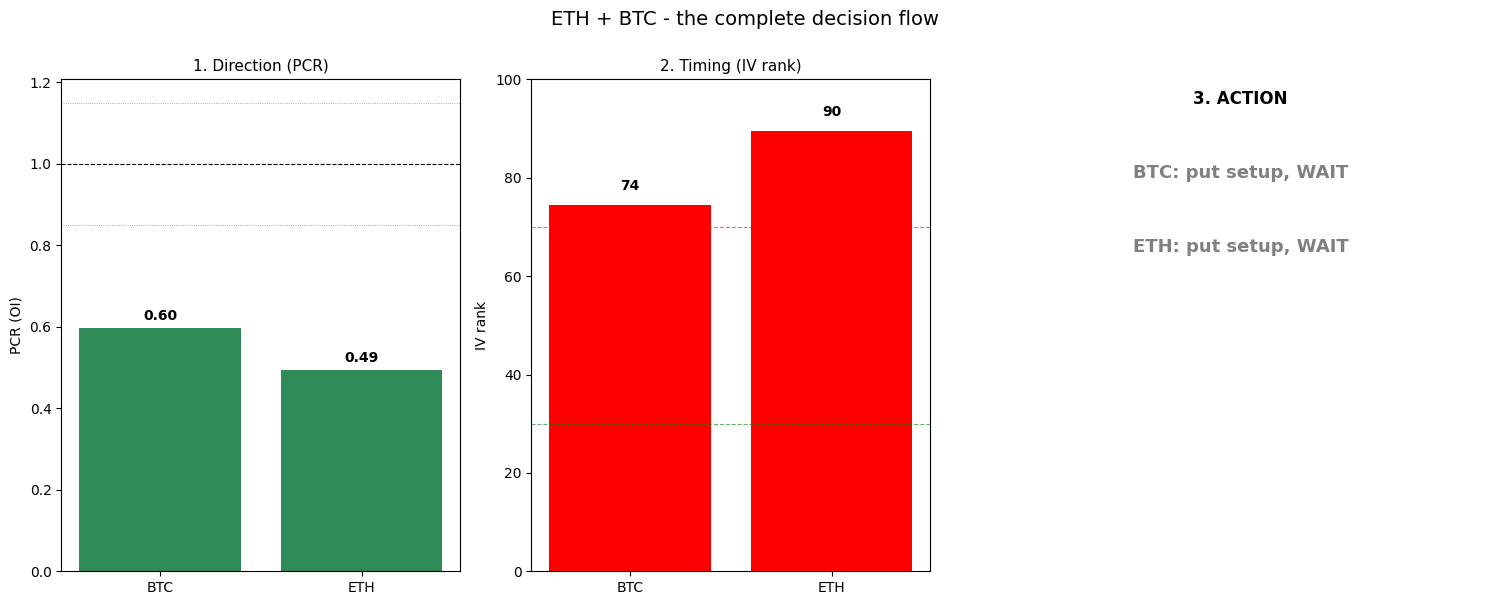

In [54]:
# Final summary: PCR direction + IV rank timing = the answer
fig = plt.figure(figsize=(15, 6))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.2])

# Panel 1: PCR bars
ax1 = fig.add_subplot(gs[0, 0])
colors = ['seagreen' if pcr[pcr.coin==c].iloc[0]['pcr_oi'] < 0.85
          else ('crimson' if pcr[pcr.coin==c].iloc[0]['pcr_oi'] > 1.15 else 'gray')
          for c in active]
vals = [pcr[pcr.coin==c].iloc[0]['pcr_oi'] for c in active]
bars = ax1.bar(active, vals, color=colors)
ax1.axhline(1.0, color='black', lw=0.8, ls='--')
ax1.axhline(1.15, color='red', lw=0.6, ls=':', alpha=0.6)
ax1.axhline(0.85, color='green', lw=0.6, ls=':', alpha=0.6)
ax1.set_ylabel('PCR (OI)')
ax1.set_title('1. Direction (PCR)', fontsize=11)
for b, v in zip(bars, vals):
    ax1.text(b.get_x() + b.get_width()/2, v + 0.02, f'{v:.2f}',
             ha='center', fontweight='bold')

# Panel 2: IV rank bars
ax2 = fig.add_subplot(gs[0, 1])
iv_ranks_plot = []
for cur in active:
    vals_iv = fetch_iv_index(cur)
    if len(vals_iv) < 5: iv_ranks_plot.append(50)
    else:
        lo, hi = min(vals_iv), max(vals_iv)
        iv_ranks_plot.append((vals_iv[-1] - lo) / (hi - lo) * 100 if hi > lo else 50)

colors2 = ['green' if r < 30 else ('gold' if r < 60 else 'red') for r in iv_ranks_plot]
bars2 = ax2.bar(active, iv_ranks_plot, color=colors2)
ax2.axhline(30, color='green', ls='--', lw=0.8, alpha=0.6)
ax2.axhline(70, color='red', ls='--', lw=0.8, alpha=0.6)
ax2.set_ylim(0, 100)
ax2.set_ylabel('IV rank')
ax2.set_title('2. Timing (IV rank)', fontsize=11)
for b, v in zip(bars2, iv_ranks_plot):
    ax2.text(b.get_x() + b.get_width()/2, v + 3, f'{v:.0f}',
             ha='center', fontweight='bold')

# Panel 3: Final answer
ax3 = fig.add_subplot(gs[0, 2])
ax3.axis('off')
ax3.text(0.5, 0.95, '3. ACTION', ha='center', fontsize=12,
         fontweight='bold', transform=ax3.transAxes)
y = 0.80
for i, cur in enumerate(active):
    p = pcr[pcr.coin == cur].iloc[0]['pcr_oi']
    iv = iv_ranks_plot[i]

    if p > 1.15 and iv < 60:
        action, color = 'BUY CALLS NOW', 'green'
    elif p < 0.85 and iv < 60:
        action, color = 'BUY PUTS NOW', 'red'
    elif p > 1.15 and iv >= 60:
        action, color = 'call setup, WAIT', 'gray'
    elif p < 0.85 and iv >= 60:
        action, color = 'put setup, WAIT', 'gray'
    else:
        action, color = 'NO EDGE', 'black'

    ax3.text(0.5, y, f'{cur}: {action}', ha='center', fontsize=13,
             color=color, fontweight='bold', transform=ax3.transAxes)
    y -= 0.15

plt.suptitle('ETH + BTC - the complete decision flow', fontsize=14, y=1.0)
plt.tight_layout(); plt.show()